# CSE 572 – Data Mining
## Homework 2: Neural Networks for Song Genre Classification

### Overview

The goal of this homework is to classify songs into genre categories using neural network models. The assignment explores both **multi-class** and **multi-label classification** using song lyrics and text-based feature representations.

This notebook includes the following steps:

1. **Data Loading and Preprocessing** – Load, inspect, clean, and prepare the song dataset for classification.
2. **Feature Engineering** – Generate text features using **CountVectorizer**, **TF-IDF**, and n-gram-based representations.
3. **Multi-Class Neural Network Classification** – Train neural networks and evaluate their performance using **5-fold cross-validation**.
4. **Feature Comparison** – Compare different feature representations using training and validation accuracy.
5. **Multi-Label Neural Network Classification** – Build neural network models capable of predicting multiple genre labels for each song.
6. **Learning Rate Analysis** – Evaluate different learning rates using **sample-wise F1 score** with 5-fold cross-validation.
7. **Optimizer Analysis** – Compare **SGD, Adam, and RMSprop** optimizers.
8. **Final Model Selection** – Select the best-performing neural network configuration based on cross-validation results.
9. **Kaggle Prediction** – Train the selected model on the available training data and generate multi-label predictions for the test dataset.
10. **Submission Generation** – Create the final Kaggle submission file while preserving the required test-set identifiers and submission format.

## Setup

Import the libraries for the original PyTorch experiments, seed NumPy and PyTorch,
and limit PyTorch CPU threads for this small corpus.

In [13]:
from pathlib import Path
from IPython.display import display
import os

# Data manipulation
import pandas as pd
import numpy as np
import ast

# Text feature extraction
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Model evaluation
from sklearn.metrics import accuracy_score, f1_score

# Neural network development
import torch
import torch.nn as nn
import torch.optim as optim

# Visualization
import matplotlib.pyplot as plt

# Reproducibility
torch.set_num_threads(4)
np.random.seed(42)
torch.manual_seed(42)

print("All libraries imported successfully!")

All libraries imported successfully!


## Data

Find the three supplied CSVs and verify the specified sizes and the submission IDs.
The notebook uses the sample submission as an ID template.

In [14]:
DATA_DIR = Path(os.environ.get("HW2_DATA_DIR", "/content" if Path("/content").is_dir() else "."))
filenames = ("train.csv", "evaluation.csv", "sample_submission.csv")
if not all((DATA_DIR / filename).is_file() for filename in filenames):
    DATA_DIR = DATA_DIR / "song-classification-cse-572-fall-2026-hw-2-nn"
missing_files = [filename for filename in filenames if not (DATA_DIR / filename).is_file()]
if missing_files:
    raise FileNotFoundError(f"Set DATA_DIR to the CSV folder. Missing at {DATA_DIR}: {missing_files}")

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "evaluation.csv")
sample_df = pd.read_csv(DATA_DIR / "sample_submission.csv")
assert len(train_df) == 2500 and len(test_df) == len(sample_df) == 627
assert train_df.total.is_unique and test_df.total.is_unique and sample_df.total.is_unique
assert set(test_df.total) == set(sample_df.total)
print(f"Loaded {len(train_df):,} labeled songs and {len(test_df):,} evaluation songs.")

Loaded 2,500 labeled songs and 627 evaluation songs.


## Question 1 · Multi-class classification

Choose the first stored genre for each song. Compare unigram counts and unigram TF-IDF
using the same 128–128 ReLU network and five shuffled folds. Each vectorizer is fitted
on the training portion of its fold. The table and figure summarize accuracy.

### Label Preprocessing for Multi-Class Classification

This code converts the `second_label` column from strings into Python lists. Since multi-class classification requires one label per song, the first genre is selected as the target label. Finally, it displays sample records and the distribution of songs across different genres.

In [15]:
# Convert label strings into Python lists
train_df["labels"] = train_df["second_label"].apply(ast.literal_eval)

# Select one label for Question 1 (multi-class)
train_df["single_label"] = train_df["labels"].apply(lambda labels: labels[0])

# Inspect the result
display(train_df[["second_label", "labels", "single_label"]].head())

# Count songs per selected genre
print("\nGenre distribution:")
print(train_df["single_label"].value_counts())

,second_label,labels,single_label
0,"[""hiphop""]",[hiphop],hiphop
1,"[""jazz""]",[jazz],jazz
2,"[""pop""]",[pop],pop
3,"[""edm"", ""rock""]","[edm, rock]",edm
4,"[""pop""]",[pop],pop



Genre distribution:
single_label
pop          965
hiphop       397
other        258
edm          209
rock         208
country      136
rb           134
folk          57
metal         40
kpop          37
jazz          30
latin         16
reggae        10
classical      3
Name: count, dtype: int64


### Question 1(a): Neural Network with CountVectorizer

This experiment uses CountVectorizer to transform song lyrics into numerical word-frequency features. A neural network with two hidden layers of 128 neurons each is trained to classify songs into 14 genres. Five-fold cross-validation is used to evaluate the model's training and validation accuracy.

In [16]:
# Prepare lyrics and target labels
X_text = train_df["lyrics_clean"].fillna("").astype(str)
y = train_df["single_label"]

# Display dataset information
print("Number of songs:", len(X_text))
print("Number of genres:", y.nunique())
print("Missing lyrics:", train_df["lyrics_clean"].isna().sum())

Number of songs: 2500
Number of genres: 14
Missing lyrics: 0


### Question 1(a): Neural Network Architecture

This code defines a fully connected neural network for multi-class song genre classification using PyTorch. The model contains two hidden layers, each with 128 neurons and ReLU activation functions. The input layer receives numerical features extracted from song lyrics, while the output layer produces scores for the 14 possible genres.

In [17]:
# Define the neural network architecture
class SongClassifier(nn.Module):
    def __init__(self, input_size, num_classes):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.network(x)

### Neural Network Training and Evaluation

This code defines a function to train and evaluate the neural network. It uses the Adam optimizer and CrossEntropyLoss to update model parameters and minimize classification errors. After training, the function calculates the training and validation accuracy to measure model performance.

In [18]:
# Function to train and evaluate the neural network
def train_evaluate_model(X_train, X_val, y_train, y_val,
                         epochs=20, learning_rate=0.001):

    # Convert features and labels into PyTorch tensors
    X_train = torch.tensor(X_train, dtype=torch.float32)
    X_val = torch.tensor(X_val, dtype=torch.float32)
    y_train = torch.tensor(y_train, dtype=torch.long)
    y_val = torch.tensor(y_val, dtype=torch.long)

    # Initialize the neural network
    model = SongClassifier(
        input_size=X_train.shape[1],
        num_classes=14
    )

    # Define loss function and optimizer
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    # Train the model
    for epoch in range(epochs):
        model.train()

        optimizer.zero_grad()
        outputs = model(X_train)
        loss = criterion(outputs, y_train)

        loss.backward()
        optimizer.step()

    # Evaluate model performance
    model.eval()

    with torch.no_grad():
        train_predictions = model(X_train).argmax(dim=1)
        val_predictions = model(X_val).argmax(dim=1)

    # Calculate accuracy
    train_accuracy = accuracy_score(
        y_train.numpy(), train_predictions.numpy()
    )

    val_accuracy = accuracy_score(
        y_val.numpy(), val_predictions.numpy()
    )

    return train_accuracy, val_accuracy

### CountVectorizer with 5-Fold Cross-Validation

This experiment converts song lyrics into numerical word-count features using CountVectorizer. The dataset is divided into five folds, and the neural network is trained and evaluated five times. The vectorizer is fitted only on the training portion of each fold to prevent data leakage. Finally, the mean and standard deviation of training and validation accuracy are calculated.

In [19]:
from sklearn.model_selection import KFold
from sklearn.preprocessing import LabelEncoder

# Encode genre labels as integers
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Initialize 5-fold cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Store accuracy results
train_accuracies = []
val_accuracies = []

# Perform 5-fold cross-validation
for fold, (train_idx, val_idx) in enumerate(kf.split(X_text), 1):

    # Split lyrics and labels
    X_train_text = X_text.iloc[train_idx]
    X_val_text = X_text.iloc[val_idx]

    y_train = y_encoded[train_idx]
    y_val = y_encoded[val_idx]

    # Extract word-count features
    vectorizer = CountVectorizer(max_features=5000)

    X_train = vectorizer.fit_transform(
        X_train_text
    ).toarray()

    X_val = vectorizer.transform(
        X_val_text
    ).toarray()

    # Train and evaluate the neural network
    train_acc, val_acc = train_evaluate_model(
        X_train, X_val, y_train, y_val
    )

    # Save results
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(
        f"Fold {fold}: "
        f"Training Accuracy = {train_acc:.4f}, "
        f"Validation Accuracy = {val_acc:.4f}"
    )

# Calculate mean and standard deviation
print("\nCountVectorizer Results")
print(f"Mean Training Accuracy: {np.mean(train_accuracies):.4f}")
print(f"Training Std: {np.std(train_accuracies):.4f}")
print(f"Mean Validation Accuracy: {np.mean(val_accuracies):.4f}")
print(f"Validation Std: {np.std(val_accuracies):.4f}")

Fold 1: Training Accuracy = 0.6280, Validation Accuracy = 0.4700
Fold 2: Training Accuracy = 0.6620, Validation Accuracy = 0.4660
Fold 3: Training Accuracy = 0.6780, Validation Accuracy = 0.4920
Fold 4: Training Accuracy = 0.6775, Validation Accuracy = 0.4600
Fold 5: Training Accuracy = 0.6650, Validation Accuracy = 0.4880

CountVectorizer Results
Mean Training Accuracy: 0.6621
Training Std: 0.0182
Mean Validation Accuracy: 0.4752
Validation Std: 0.0126


### CountVectorizer results

The printed scores summarize variation across folds. Compare the training and validation means to assess how well the count features generalize.

### Question 1(b): TF-IDF Feature Exploration

This experiment uses TF-IDF to extract numerical features from song lyrics based on word importance. The same neural network architecture with two hidden layers of 128 neurons is evaluated using 5-fold cross-validation. The training and validation accuracy are compared with the CountVectorizer baseline to determine which feature representation performs better.

In [20]:
# Store TF-IDF accuracy results
tfidf_train_accuracies = []
tfidf_val_accuracies = []

# Perform 5-fold cross-validation
for fold, (train_idx, val_idx) in enumerate(kf.split(X_text), 1):

    # Split lyrics and labels
    X_train_text = X_text.iloc[train_idx]
    X_val_text = X_text.iloc[val_idx]

    y_train = y_encoded[train_idx]
    y_val = y_encoded[val_idx]

    # Extract TF-IDF features
    vectorizer = TfidfVectorizer(max_features=5000)

    X_train = vectorizer.fit_transform(
        X_train_text
    ).toarray()

    X_val = vectorizer.transform(
        X_val_text
    ).toarray()

    # Train and evaluate the neural network
    train_acc, val_acc = train_evaluate_model(
        X_train, X_val, y_train, y_val
    )

    # Store accuracy results
    tfidf_train_accuracies.append(train_acc)
    tfidf_val_accuracies.append(val_acc)

    print(
        f"Fold {fold}: "
        f"Training Accuracy = {train_acc:.4f}, "
        f"Validation Accuracy = {val_acc:.4f}"
    )

# Calculate mean and standard deviation
print("\nTF-IDF Results")
print(f"Mean Training Accuracy: {np.mean(tfidf_train_accuracies):.4f}")
print(f"Training Std: {np.std(tfidf_train_accuracies):.4f}")
print(f"Mean Validation Accuracy: {np.mean(tfidf_val_accuracies):.4f}")
print(f"Validation Std: {np.std(tfidf_val_accuracies):.4f}")

Fold 1: Training Accuracy = 0.3940, Validation Accuracy = 0.3540
Fold 2: Training Accuracy = 0.3890, Validation Accuracy = 0.4040
Fold 3: Training Accuracy = 0.3880, Validation Accuracy = 0.3780
Fold 4: Training Accuracy = 0.3865, Validation Accuracy = 0.3840
Fold 5: Training Accuracy = 0.3830, Validation Accuracy = 0.4120

TF-IDF Results
Mean Training Accuracy: 0.3881
Training Std: 0.0036
Mean Validation Accuracy: 0.3864
Validation Std: 0.0205


### TF-IDF results

TF-IDF reweights words using document frequency estimated within each training fold. Use the same accuracy metric and fold assignments for the two representations.

### Question 1(c): Feature Generation

Two feature extraction methods were used to convert song lyrics into numerical representations:

**1. CountVectorizer:** This method converts song lyrics into numerical vectors based on word frequencies. A maximum of 5,000 features was used to represent the most frequent vocabulary terms learned from the training data.

**2. TF-IDF (Term Frequency–Inverse Document Frequency):** This method represents song lyrics by assigning weights to words based on their frequency within a song and their importance across the training corpus. A maximum of 5,000 features was used.

Missing lyrics were handled by replacing null values with empty strings. Both feature extraction methods were fitted separately on the training portion of each cross-validation fold to prevent data leakage. The resulting feature vectors were used as input to a neural network containing two hidden layers of 128 neurons each.

### Question 1(d): Feature Comparison

The following table summarizes the mean training and validation accuracy, along with their standard deviations, for CountVectorizer and TF-IDF using 5-fold cross-validation.

In [21]:
# Create a comparison table
results_df = pd.DataFrame({
    "Feature Method": ["CountVectorizer", "TF-IDF"],
    "Training Accuracy": [
        np.mean(train_accuracies),
        np.mean(tfidf_train_accuracies)
    ],
    "Training Std": [
        np.std(train_accuracies),
        np.std(tfidf_train_accuracies)
    ],
    "Validation Accuracy": [
        np.mean(val_accuracies),
        np.mean(tfidf_val_accuracies)
    ],
    "Validation Std": [
        np.std(val_accuracies),
        np.std(tfidf_val_accuracies)
    ]
})

display(results_df.round(4))

,Feature Method,Training Accuracy,Training Std,Validation Accuracy,Validation Std
0,CountVectorizer,0.6621,0.0182,0.4752,0.0126
1,TF-IDF,0.3881,0.0036,0.3864,0.0205


### Question 1(e): Feature Extraction Performance Visualization

The following bar chart compares the mean training and validation accuracy obtained using CountVectorizer and TF-IDF. The error bars represent the standard deviation across five cross-validation folds. This visualization helps identify the better-performing feature extraction method and illustrates differences between training and validation performance.

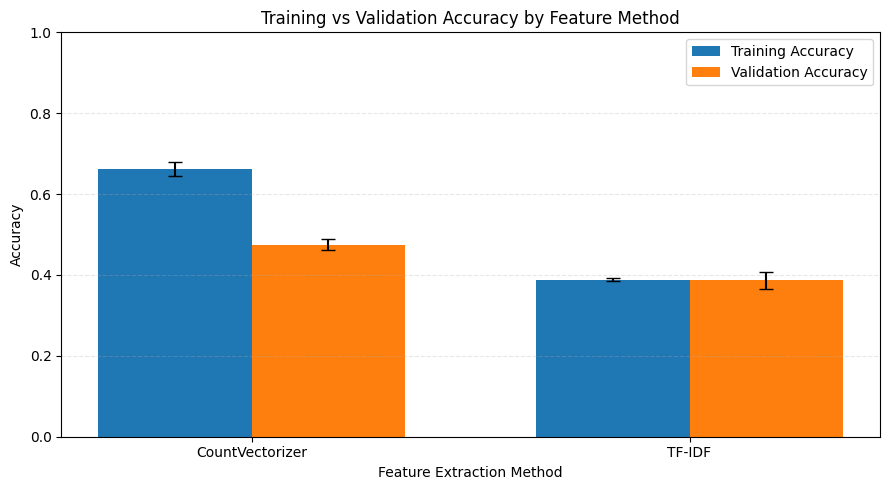

In [22]:
# Extract results from the comparison table
methods = results_df["Feature Method"]

train_means = results_df["Training Accuracy"]
val_means = results_df["Validation Accuracy"]

train_stds = results_df["Training Std"]
val_stds = results_df["Validation Std"]

# Define bar positions
x = np.arange(len(methods))
width = 0.35

# Create bar chart
plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    train_means,
    width,
    yerr=train_stds,
    capsize=5,
    label="Training Accuracy"
)

plt.bar(
    x + width / 2,
    val_means,
    width,
    yerr=val_stds,
    capsize=5,
    label="Validation Accuracy"
)

# Customize chart
plt.xlabel("Feature Extraction Method")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy by Feature Method")

plt.xticks(x, methods)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### Feature comparison

The table and bar chart compare the mean training and validation accuracy under the same architecture. Count features produced the higher validation accuracy in the recorded experiment.

## Question 2 · Multi-label neural network training

Retain every label in a 14-column multi-hot target. Use independent sigmoid outputs
with binary cross-entropy and compare all seven learning rates and three optimizers
using five-fold sample-wise F1. This experiment applies a fixed 0.5 threshold.

### Question 2(a): Multi-Label Data Preparation

This section prepares the song genre labels for multi-label classification. MultiLabelBinarizer converts each song's list of genres into a binary vector representing the 14 possible categories. Each value indicates whether a particular genre is associated with the song, allowing the neural network to predict multiple genres simultaneously.

In [23]:
from sklearn.preprocessing import MultiLabelBinarizer

# Convert genre lists into binary vectors
mlb = MultiLabelBinarizer()
Y_multi = mlb.fit_transform(train_df["labels"])

# Display dataset information
print("Number of genres:", len(mlb.classes_))
print("Multi-label target shape:", Y_multi.shape)

# Display genre names
print("\nGenre classes:")
print(mlb.classes_)

# Display sample targets
display(pd.DataFrame(
    Y_multi[:5],
    columns=mlb.classes_
))

Number of genres: 14
Multi-label target shape: (2500, 14)

Genre classes:
['classical' 'country' 'edm' 'folk' 'hiphop' 'jazz' 'kpop' 'latin' 'metal'
 'other' 'pop' 'rb' 'reggae' 'rock']


,classical,country,edm,folk,hiphop,jazz,kpop,latin,metal,other,pop,rb,reggae,rock
0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,1,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,1,0,0,0
3,0,0,1,0,0,0,0,0,0,0,0,0,0,1
4,0,0,0,0,0,0,0,0,0,0,1,0,0,0


### Question 2(a): Neural Network Parameter Settings

For multi-label classification, a fully connected neural network with two hidden layers of 128 neurons each is used. ReLU activation functions are applied to the hidden layers, and the output layer contains 14 neurons corresponding to the possible song genres.

CountVectorizer with a maximum vocabulary size of 5,000 is selected for feature extraction based on its performance in Question 1. Binary Cross-Entropy with Logits (BCEWithLogitsLoss) is used as the loss function because each song may belong to multiple genres.

The initial training configuration uses 20 epochs, a learning rate of 0.001, and the Adam optimizer. Different learning rates and optimizers will be evaluated using 5-fold cross-validation. Model performance will be measured using sample-wise F1-score.

In [24]:
# Function to train and evaluate multi-label classification
def train_evaluate_multilabel(
    X_train, X_val, y_train, y_val,
    epochs=20, learning_rate=0.001,
    optimizer_name="Adam"
):

    # Convert data into PyTorch tensors
    X_train = torch.tensor(X_train, dtype=torch.float32)
    X_val = torch.tensor(X_val, dtype=torch.float32)

    y_train = torch.tensor(y_train, dtype=torch.float32)
    y_val = torch.tensor(y_val, dtype=torch.float32)

    # Initialize neural network
    model = SongClassifier(
        input_size=X_train.shape[1],
        num_classes=14
    )

    # Define loss function
    criterion = nn.BCEWithLogitsLoss()

    # Select optimizer
    if optimizer_name == "SGD":
        optimizer = optim.SGD(
            model.parameters(), lr=learning_rate
        )
    elif optimizer_name == "RMSprop":
        optimizer = optim.RMSprop(
            model.parameters(), lr=learning_rate
        )
    elif optimizer_name == "Adam":
        optimizer = optim.Adam(
            model.parameters(), lr=learning_rate
        )
    else:
        raise ValueError("Unsupported optimizer")

    # Train the model
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()

        outputs = model(X_train)
        loss = criterion(outputs, y_train)

        loss.backward()
        optimizer.step()

    # Evaluate the model
    model.eval()

    with torch.no_grad():
        train_probs = torch.sigmoid(model(X_train))
        val_probs = torch.sigmoid(model(X_val))

        train_preds = (train_probs >= 0.5).int().numpy()
        val_preds = (val_probs >= 0.5).int().numpy()

    # Calculate sample-wise F1
    train_f1 = f1_score(
        y_train.numpy(), train_preds,
        average="samples", zero_division=0
    )

    val_f1 = f1_score(
        y_val.numpy(), val_preds,
        average="samples", zero_division=0
    )

    return train_f1, val_f1

### Question 2(b): Learning Rate Exploration Using 5-Fold Cross-Validation

This experiment evaluates the effect of seven learning rates on multi-label neural network performance. CountVectorizer is used to extract word-frequency features, and the Adam optimizer is applied with 20 training epochs. Five-fold cross-validation is performed for each learning rate, and the mean and standard deviation of training and validation sample-wise F1-scores are calculated to identify the best learning rate.

In [25]:
# Define candidate learning rates
learning_rates = [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1]

# Store experiment results
lr_results = []

# Prepare folds once for consistent comparisons
fold_data = []

for train_idx, val_idx in kf.split(X_text):

    # Split lyrics and multi-label targets
    X_train_text = X_text.iloc[train_idx]
    X_val_text = X_text.iloc[val_idx]

    y_train = Y_multi[train_idx]
    y_val = Y_multi[val_idx]

    # Fit CountVectorizer only on training data
    vectorizer = CountVectorizer(max_features=5000)

    X_train = vectorizer.fit_transform(
        X_train_text
    ).toarray()

    X_val = vectorizer.transform(
        X_val_text
    ).toarray()

    fold_data.append((X_train, X_val, y_train, y_val))

# Evaluate each learning rate
for lr in learning_rates:

    train_scores = []
    val_scores = []

    for X_train, X_val, y_train, y_val in fold_data:

        train_f1, val_f1 = train_evaluate_multilabel(
            X_train, X_val, y_train, y_val,
            epochs=20,
            learning_rate=lr,
            optimizer_name="Adam"
        )

        train_scores.append(train_f1)
        val_scores.append(val_f1)

    # Save mean and standard deviation
    lr_results.append({
        "Learning Rate": lr,
        "Training F1": np.mean(train_scores),
        "Training Std": np.std(train_scores),
        "Validation F1": np.mean(val_scores),
        "Validation Std": np.std(val_scores)
    })

    print(
        f"LR={lr}: "
        f"Train F1={np.mean(train_scores):.4f}, "
        f"Validation F1={np.mean(val_scores):.4f}"
    )

# Create results table
lr_results_df = pd.DataFrame(lr_results)

print("\nLearning Rate Comparison Results:")
display(lr_results_df.round(4))

LR=0.0001: Train F1=0.2029, Validation F1=0.1925
LR=0.0003: Train F1=0.1317, Validation F1=0.1130
LR=0.001: Train F1=0.2285, Validation F1=0.1292
LR=0.003: Train F1=0.5005, Validation F1=0.3141
LR=0.01: Train F1=0.7533, Validation F1=0.3815
LR=0.03: Train F1=0.2223, Validation F1=0.1834
LR=0.1: Train F1=0.0000, Validation F1=0.0003

Learning Rate Comparison Results:


,Learning Rate,Training F1,Training Std,Validation F1,Validation Std
0,0.0001,0.2029,0.1132,0.1925,0.1142
1,0.0003,0.1317,0.1508,0.1130,0.1409
2,0.0010,0.2285,0.0905,0.1292,0.0689
3,0.0030,0.5005,0.0203,0.3141,0.0174
4,0.0100,0.7533,0.0661,0.3815,0.0340
5,0.0300,0.2223,0.1740,0.1834,0.1614
6,0.1000,0.0000,0.0000,0.0003,0.0002


### Question 2(b): Learning Rate Performance Visualization

This line chart illustrates the effect of different learning rates on the neural network's training and validation sample-wise F1-scores. The x-axis represents the learning rate, while the y-axis represents the mean F1-score across five folds. The visualization helps identify the learning rate that produces the best validation performance.

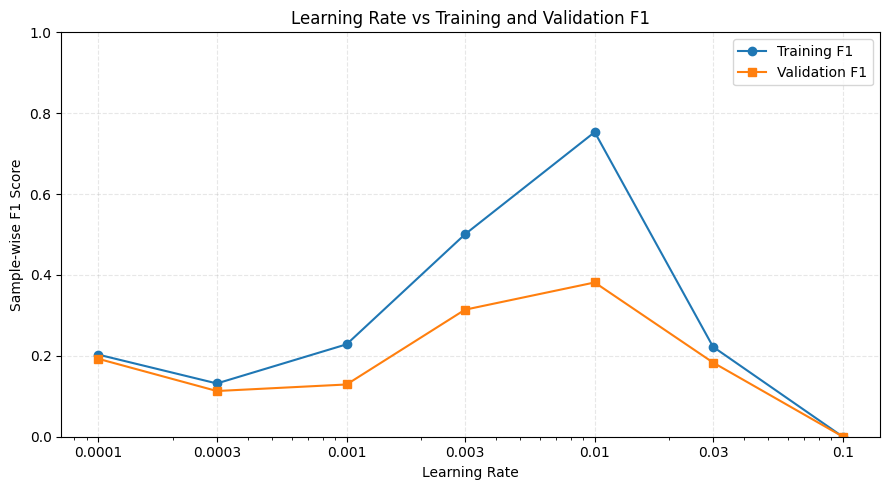

In [26]:
# Plot training and validation F1 by learning rate
plt.figure(figsize=(9, 5))

plt.plot(
    lr_results_df["Learning Rate"],
    lr_results_df["Training F1"],
    marker="o",
    label="Training F1"
)

plt.plot(
    lr_results_df["Learning Rate"],
    lr_results_df["Validation F1"],
    marker="s",
    label="Validation F1"
)

plt.xscale("log")
plt.xlabel("Learning Rate")
plt.ylabel("Sample-wise F1 Score")
plt.title("Learning Rate vs Training and Validation F1")

plt.ylim(0, 1)
plt.xticks(learning_rates, [str(lr) for lr in learning_rates])
plt.grid(True, linestyle="--", alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

### Learning-rate comparison

Select the learning rate with the highest mean validation sample-wise F1. The line plot uses a logarithmic learning-rate axis to show all seven settings.

### Question 2(c): Optimizer Comparison Using 5-Fold Cross-Validation

This experiment compares three optimization algorithms: SGD, RMSprop, and Adam. The learning rate is fixed at 0.01 based on the previous experiment. Each optimizer is evaluated using 5-fold cross-validation with the same neural network architecture, CountVectorizer features, and 20 training epochs. The mean and standard deviation of training and validation sample-wise F1-scores are calculated to identify the best-performing optimizer.

In [27]:
# Define optimizers to compare
optimizers = ["SGD", "RMSprop", "Adam"]

# Use the best learning rate from Question 2(b)
best_lr = lr_results_df.loc[
    lr_results_df["Validation F1"].idxmax(),
    "Learning Rate"
]

# Store optimizer results
optimizer_results = []

# Evaluate each optimizer
for optimizer_name in optimizers:

    train_scores = []
    val_scores = []

    # Use the same prepared cross-validation folds
    for X_train, X_val, y_train, y_val in fold_data:

        train_f1, val_f1 = train_evaluate_multilabel(
            X_train,
            X_val,
            y_train,
            y_val,
            epochs=20,
            learning_rate=best_lr,
            optimizer_name=optimizer_name
        )

        train_scores.append(train_f1)
        val_scores.append(val_f1)

    # Store mean and standard deviation
    optimizer_results.append({
        "Optimizer": optimizer_name,
        "Training F1": np.mean(train_scores),
        "Training Std": np.std(train_scores),
        "Validation F1": np.mean(val_scores),
        "Validation Std": np.std(val_scores)
    })

    print(
        f"{optimizer_name}: "
        f"Train F1={np.mean(train_scores):.4f}, "
        f"Validation F1={np.mean(val_scores):.4f}"
    )

# Create optimizer comparison table
optimizer_results_df = pd.DataFrame(optimizer_results)

print("\nOptimizer Comparison Results:")
display(optimizer_results_df.round(4))

SGD: Train F1=0.1502, Validation F1=0.1550
RMSprop: Train F1=0.3671, Validation F1=0.2744
Adam: Train F1=0.6986, Validation F1=0.3701

Optimizer Comparison Results:


,Optimizer,Training F1,Training Std,Validation F1,Validation Std
0,SGD,0.1502,0.0464,0.1550,0.0435
1,RMSprop,0.3671,0.1270,0.2744,0.1438
2,Adam,0.6986,0.0785,0.3701,0.0319


### Question 2(c): Optimizer Performance Visualization

This bar chart compares the mean training and validation sample-wise F1-scores for SGD, RMSprop, and Adam using 5-fold cross-validation. Error bars represent the standard deviation across the five folds. The comparison helps identify the optimizer that provides the best validation performance.

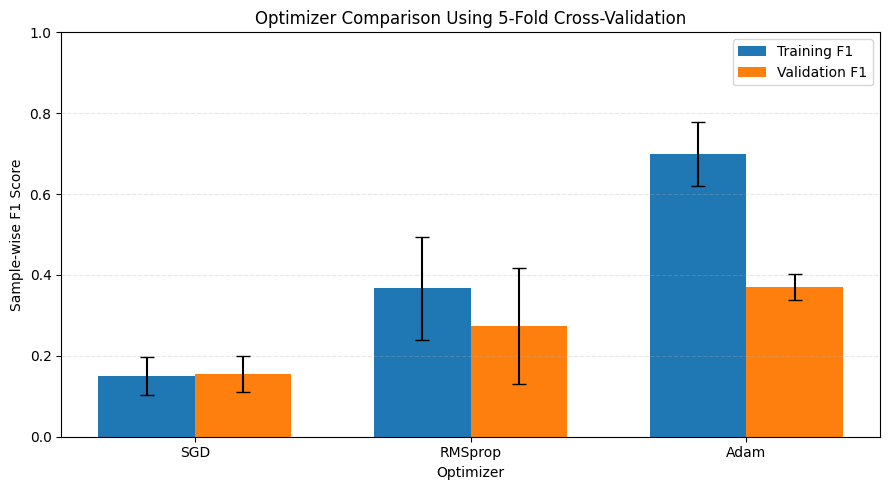

In [28]:
# Extract optimizer comparison results
methods = optimizer_results_df["Optimizer"]

train_means = optimizer_results_df["Training F1"]
val_means = optimizer_results_df["Validation F1"]

train_stds = optimizer_results_df["Training Std"]
val_stds = optimizer_results_df["Validation Std"]

# Define bar positions
x = np.arange(len(methods))
width = 0.35

# Create bar chart
plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    train_means,
    width,
    yerr=train_stds,
    capsize=5,
    label="Training F1"
)

plt.bar(
    x + width / 2,
    val_means,
    width,
    yerr=val_stds,
    capsize=5,
    label="Validation F1"
)

# Customize chart
plt.xlabel("Optimizer")
plt.ylabel("Sample-wise F1 Score")
plt.title("Optimizer Comparison Using 5-Fold Cross-Validation")

plt.xticks(x, methods)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### Optimizer comparison

The optimizers were run independently with a fixed learning rate selected from the sweep. An optimizer's new training run can differ from its learning-rate sweep run because the model initialization is drawn again. Compare validation F1 and its deviation across folds.

## Question 3 · Original lyrics-only baseline

This experiment preserves the original V3 validation comparison before the improved
features. The dropout network uses count features, Adam at 0.01, 30 epochs, and
out-of-fold predictions to compare thresholds. The threshold sweep is exploratory
because the same validation probabilities are used to choose and score thresholds.

### Define the two-layer dropout network used by the original lyrics-only model.

In [29]:
# Neural network architecture with dropout
class DropoutSongClassifier(nn.Module):
    def __init__(self, input_size, num_classes, dropout_rate):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.network(x)

print("Dropout neural network defined successfully!")

Dropout neural network defined successfully!


### Refit the lyrics-only model in each training fold and tune its prediction threshold.

In [30]:
# Validate the V3 lyrics-only baseline
oof_v3 = np.zeros(Y_multi.shape, dtype=np.float32)

texts = train_df["lyrics_clean"].fillna("").astype(str)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

for fold, (train_idx, val_idx) in enumerate(kf.split(texts), 1):
    vectorizer = CountVectorizer(max_features=5000)

    X_tr = torch.tensor(
        vectorizer.fit_transform(texts.iloc[train_idx]).toarray(),
        dtype=torch.float32
    )
    X_val = torch.tensor(
        vectorizer.transform(texts.iloc[val_idx]).toarray(),
        dtype=torch.float32
    )
    y_tr = torch.tensor(Y_multi[train_idx], dtype=torch.float32)

    torch.manual_seed(42)
    model = DropoutSongClassifier(X_tr.shape[1], 14, 0.2)
    optimizer = optim.Adam(model.parameters(), lr=0.01)
    criterion = nn.BCEWithLogitsLoss()

    for epoch in range(30):
        model.train()
        optimizer.zero_grad()
        loss = criterion(model(X_tr), y_tr)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        oof_v3[val_idx] = torch.sigmoid(model(X_val)).numpy()

    print(f"Fold {fold} completed")

# Compare thresholds using out-of-fold predictions
results = []

for threshold in np.arange(0.10, 0.301, 0.01):
    preds = (oof_v3 >= threshold).astype(int)

    # Match the submission fallback rule
    empty = np.where(preds.sum(axis=1) == 0)[0]
    for i in empty:
        preds[i, np.argmax(oof_v3[i])] = 1

    results.append({
        "Threshold": round(float(threshold), 2),
        "Validation F1": f1_score(
            Y_multi, preds, average="samples", zero_division=0
        )
    })

v3_threshold_results = pd.DataFrame(results)

display(
    v3_threshold_results.sort_values(
        "Validation F1", ascending=False
    ).head(10).round(4)
)

Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed


,Threshold,Validation F1
17,0.27,0.5035
9,0.19,0.5029
18,0.28,0.5028
20,0.30,0.5028
16,0.26,0.5027
12,0.22,0.5022
15,0.25,0.5021
14,0.24,0.5020
11,0.21,0.5015
10,0.20,0.5014


## Question 3 · Final hybrid network

The improved features summarize lyrics, artist and song matches, source, language, and
release dates. Matching features use labels of other training songs. Each training row
is excluded from its own label-based features. Every validation song is transformed
against its training fold. The final classifier is a regularized hybrid MLP.

## 1. Environment and data location

Import the numerical, text-processing, and neural-network libraries. Set the data directory
and define the 14 output genres in a stable order.

In [31]:
import json
import os
import re
import unicodedata
import warnings
from collections import defaultdict
from pathlib import Path
from urllib.parse import unquote, urlsplit

os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
os.environ.setdefault("VECLIB_MAXIMUM_THREADS", "2")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("MKL_NUM_THREADS", "2")

import numpy as np
import pandas as pd
from scipy.linalg import cho_factor, cho_solve
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import KFold
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
from threadpoolctl import threadpool_limits

CLASSES = sorted(
    "pop rock hiphop rb country jazz edm classical kpop latin folk metal reggae other".split()
)
SEED = 42
warnings.filterwarnings("ignore", category=ConvergenceWarning)

## 2. Read labels and prepare row-level features

Parse every label in `second_label` into a multi-hot vector. Normalize artist names,
prepare lyric style measurements, and extract release-day and source URL components.
Use song IDs to validate and align predictions. The features do not use song IDs.

In [32]:
def clean_name(value):
    folded = unicodedata.normalize("NFKD", value.casefold())
    plain = "".join(c for c in folded if not unicodedata.combining(c))
    return " ".join(re.findall(r"[^\W_]+", plain.replace("&", " and ")))


def artist_parts(value):
    return [
        part.strip()
        for part in re.split(r"\s*(?:[,;&/]|\b(?:feat(?:uring)?|ft|with)\.?\s+|\s+x\s+)\s*", value)
        if part.strip()
    ]


def source_fields(value):
    url = urlsplit(value if "://" in value else "//" + value)
    host = (url.hostname or "").removeprefix("www.")
    path = unquote(url.path).casefold().strip("/")
    first = path.split("/", 1)[0]
    group = first if first in {"lyrics", "artist", "album", "track"} else ""
    group = " ".join([host, group]).strip()
    return host, group, (host + "/" + path if path else "")


def lyric_style(text):
    words = re.findall(r"[^\W_]+", text.lower())
    length = max(1, len(words))
    unique = len(set(words))
    word_pairs = list(zip(words, words[1:]))
    groups = [
        "i im ive me my mine myself",
        "you ya your youre yours yourself",
        "love baby heart forever kiss",
        "fuck fucking fucked shit bitch nigga niggas motherfucker",
        "money cash racks bands opp opps gang gun guns diamonds",
        "dance dancing club beat tonight body floor dj rhythm",
        "jesus god lord bless amen pray heaven",
        "truck whiskey beer road river mama daddy home",
        "death blood dead kill hell pain tears soul dark",
        "uh huh ay ayy yo yuh yeah oh ooh ah la na",
        "the a of is and was are were this it",
        "dil hai tera mera main mein nahi kya tu tenu ve",
    ]
    amounts = [sum(w in group.split() for w in words) for group in groups]
    pieces = re.split(r"[,.;!?\n]+", text)
    pieces = [v.strip() for v in pieces if v.strip()]
    return [
        np.log1p(len(text)),
        np.log1p(length),
        np.log1p(unique),
        unique / length,
        len(set(word_pairs)) / length,
        len(set(zip(words, words[1:], words[2:]))) / length,
        len(set(pieces)) / max(1, len(pieces)),
        np.mean([len(w) for w in words]) if words else 0.0,
        sum(ord(c) > 127 for c in text) / max(1, len(text)),
        sum(w.isnumeric() for w in words) / length,
        np.log1p(len(pieces)),
        *[np.log1p(x) for x in amounts],
        *[x / length for x in amounts],
    ]


def read_inputs(data_dir):
    train = pd.read_csv(data_dir / "train.csv", dtype={"total": str})
    evaluation = pd.read_csv(data_dir / "evaluation.csv", dtype={"total": str})
    template = pd.read_csv(data_dir / "sample_submission.csv", dtype={"total": str})
    labels = train["second_label"].map(json.loads)
    assert labels.map(bool).all()
    assert set(labels.explode()) == set(CLASSES)
    assert train["total"].is_unique and template["total"].is_unique and evaluation["total"].is_unique
    assert set(train["total"]).isdisjoint(evaluation["total"])
    assert set(template["total"]) == set(evaluation["total"])
    target = MultiLabelBinarizer(classes=CLASSES).fit_transform(labels).astype(np.float32)
    songs = pd.concat([train, evaluation], ignore_index=True).fillna("")
    for name in ["artist", "title", "language", "lyrics_clean", "source"]:
        songs[name] = songs[name].astype(str)
    songs["artist_key"] = songs["artist"].map(clean_name)
    songs["title_key"] = songs["title"].map(clean_name)
    songs["language_key"] = songs["language"].map(clean_name)
    songs[["source_host", "source_group", "source_path"]] = pd.DataFrame(
        songs["source"].map(source_fields).tolist(), index=songs.index
    )
    songs["date_days"] = (
        (pd.to_datetime(songs["release_date"], errors="coerce") - pd.Timestamp("2025-08-01"))
        .dt.days.fillna(-1000).astype(int)
    )
    return songs, target, evaluation, template

## 3. Build features within each training split

Fit word and character TF-IDF on the training songs. Measure shared artists, artist similarities,
close release dates, similar song versions, shared source domains, and language. Turn these
matches into smoothed genre frequencies using the training labels. Exclude the current song
from its own genre features. Use leave-one-out kernel ridge scores for training songs and
training-reference scores for validation or evaluation songs.

In [33]:
def tfidf_similarity(reference, queries, **params):
    vectorizer = TfidfVectorizer(dtype=np.float32, sublinear_tf=True, **params)
    train_vectors = vectorizer.fit_transform(reference)
    test_vectors = vectorizer.transform(queries)
    return (test_vectors @ train_vectors.T).toarray()


def exact_match(query, reference):
    a = np.asarray(query)
    b = np.asarray(reference)
    return ((a[:, None] == b[None, :]) & (a[:, None] != "")).astype(np.float32)


def artist_affinity(reference, queries):
    reference_keys = [clean_name(credit) for credit in reference]
    query_keys = [clean_name(credit) for credit in queries]
    phrase_trie = {}
    for credit, key in zip(reference, reference_keys):
        for phrase in {key, *(clean_name(p) for p in artist_parts(credit))}:
            if len(phrase) < 5:
                continue
            branch = phrase_trie
            for token in phrase.split():
                branch = branch.setdefault(token, {})
            branch[None] = phrase

    def known_parts(credit, key):
        parts = set(clean_name(p) for p in artist_parts(credit)) | {key}
        words = key.split()
        for i in range(len(words)):
            branch = phrase_trie
            for token in words[i:]:
                branch = branch.get(token)
                if branch is None:
                    break
                if None in branch:
                    parts.add(branch[None])
        return {part for part in parts if len(part) > 2}

    lookup = defaultdict(list)
    for col, (credit, key) in enumerate(zip(reference, reference_keys)):
        for part in known_parts(credit, key):
            lookup[part].append(col)

    out = np.zeros((len(queries), len(reference)), np.float32)
    for row, (credit, key) in enumerate(zip(queries, query_keys)):
        for part in known_parts(credit, key):
            out[row, lookup.get(part, [])] = 0.8
    # Full credit matches carry more weight than a matching collaborator.
    return np.maximum(out, exact_match(query_keys, reference_keys))


def artist_alias_similarity(reference, queries):
    similarity = tfidf_similarity(reference, queries, analyzer="char_wb", ngram_range=(2, 5))
    return np.where(similarity >= 0.65, similarity**3, 0).astype(np.float32)


def date_distance(ref, query):
    return abs(np.asarray(query)[:, None] - np.asarray(ref)[None, :])


def finite_feature_product(left, right):
    # Some BLAS builds report these warnings even when the product is finite.
    # Scope the filter to the product and still reject NaN or infinity.
    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            message=r"^(?:divide by zero|overflow|invalid value) encountered in matmul$",
            category=RuntimeWarning,
        )
        result = left @ right
    if not np.isfinite(result).all():
        raise FloatingPointError("A Q3 feature matrix product contains NaN or infinity.")
    return result


def build_features(songs, target, fit_ids, other_ids, styles):
    # The reference columns contain only songs from this training split.
    fit = songs.iloc[fit_ids]
    query_ids = np.concatenate([fit_ids, other_ids])
    query = songs.iloc[query_ids]
    y = target[fit_ids]
    n = len(fit)
    loo = np.arange(n)

    word = tfidf_similarity(
        fit.lyrics_clean, query.lyrics_clean, ngram_range=(1, 2), min_df=2, max_features=36000
    )
    char = tfidf_similarity(
        fit.lyrics_clean, query.lyrics_clean, analyzer="char", ngram_range=(3, 5),
        min_df=2, max_features=45000
    )
    title = tfidf_similarity(
        fit.title_key, query.title_key, analyzer="char_wb", ngram_range=(2, 5),
        max_features=14000
    )
    language = exact_match(query.language_key, fit.language_key)
    host = exact_match(query.source_host, fit.source_host)
    url_group = exact_match(query.source_group, fit.source_group)
    exact_url = exact_match(query.source_path, fit.source_path)
    artist = exact_match(query.artist_key, fit.artist_key)
    shared_artist = artist_affinity(fit.artist.tolist(), query.artist.tolist())
    artist_fuzzy = artist_alias_similarity(fit.artist_key, query.artist_key)
    dates = date_distance(fit.date_days, query.date_days)
    near_date = (dates <= 3).astype(np.float32)
    exact_title = exact_match(query.title_key, fit.title_key)
    same_song = np.maximum(
        np.where((word > 0.5) & (char > 0.6), np.minimum(word, char) ** 2, 0),
        np.maximum(artist * exact_title, exact_title * artist_fuzzy),
    )

    checks = {
        "artist": artist,
        "artist_same_release": artist * near_date,
        "shared_artist": shared_artist,
        "shared_artist_same_release": shared_artist * near_date,
        "shared_artist_close_release": shared_artist * np.exp(-dates / 28).astype(np.float32),
        "shared_artist_language": shared_artist * language,
        "fuzzy_artist": artist_fuzzy,
        "likely_song_version": same_song,
        "source_path": exact_url,
        "language": language,
        "source_host": host,
        "source_group": url_group,
        "host_language": host * language,
        "near_date": near_date,
        "same_day": (dates == 0).astype(np.float32),
    }
    prior = y.mean(axis=0)
    # Subtract the current song from its own fallback genre prevalence too.
    training_priors = (y.sum(axis=0) - y) / (n - 1)
    row_prior = np.tile(prior, (len(query), 1))
    row_prior[:n] = training_priors

    style = styles[query_ids]
    normalized_style = StandardScaler().fit(style[:n]).transform(style)
    metadata = [
        normalized_style.clip(-6, 6),
        ((query.date_days.to_numpy()[:, None] - 200) / 200).clip(-4, 4),
        (pd.to_numeric(query["rank"], errors="coerce").fillna(25).to_numpy()[:, None] - 25) / 25,
    ]

    # A training query must not contribute its own label to any neighborhood feature.
    for key, affinity in checks.items():
        affinity[loo, loo] = 0
        mass = affinity.sum(axis=1, keepdims=True)
        smooth = 0.8 if key in {
            "artist", "artist_same_release", "shared_artist", "shared_artist_same_release",
            "shared_artist_close_release", "shared_artist_language", "fuzzy_artist",
            "source_path", "likely_song_version"
        } else 3.0
        empirical = (finite_feature_product(affinity, y) + smooth * row_prior) / (mass + smooth)
        metadata.extend([empirical, np.log1p(mass)])

    # Kernel ridge generates text evidence. Use the analytic leave-one-out solution
    # for training rows and the corresponding train-only fit for other rows.
    semantic = []
    text_kernels = [
        (word, 0.30),
        (char, 0.35),
        (0.56 * word + 0.34 * char + 0.10 * title, 0.30),
    ]
    for kernel, alpha in text_kernels:
        k_train = kernel[:n].copy()
        k_train.flat[:: n + 1] += alpha
        factor = cho_factor(k_train, lower=True, check_finite=False)
        weights = cho_solve(factor, y - prior, check_finite=False)
        inverse_diag = cho_solve(factor, np.eye(n, dtype=np.float32), check_finite=False).diagonal()
        ridge = finite_feature_product(kernel, weights) + prior
        ridge[:n] = y - weights / inverse_diag[:, None]
        # The intercept was computed on all reference labels. Remove each row's
        # contribution to that intercept using the same leave-one-out identity.
        intercept = cho_solve(factor, np.ones(n, np.float32), check_finite=False)
        ridge[:n] += (training_priors - prior) * (intercept / inverse_diag)[:, None]
        semantic.append(ridge)

    related = 0.55 * word + 0.45 * char
    related[loo, loo] = 0
    neighbor_indices = np.argpartition(related, -35, axis=1)[:, -35:]
    similarity = np.take_along_axis(related, neighbor_indices, axis=1)
    for power in (2, 8):
        weight = similarity**power
        mass = weight.sum(axis=1, keepdims=True)
        neighbor_scores = (np.einsum("ij,ijk->ik", weight, y[neighbor_indices]) + 0.002 * row_prior) / (mass + 0.002)
        semantic.append(neighbor_scores)
    semantic.append(similarity.max(axis=1, keepdims=True))

    artist_ind = checks["shared_artist"].sum(axis=1) > 0
    meta = np.column_stack(metadata).astype(np.float32)
    semantic = np.column_stack(semantic).astype(np.float32)
    assert np.isfinite(meta).all() and np.isfinite(semantic).all()
    return meta, semantic, artist_ind

## 4. Fit the model candidates and score genre sets

Train multilayer perceptrons with ReLU hidden units and independent sigmoid genre probabilities.
Compare a lyrics model, models that emphasize metadata, and models that combine both. For each
decoder, keep labels above an absolute and relative threshold, cap the set size, and always
include the highest-scoring genre. Evaluate the mean song-level F1 across validation songs.

In [34]:
SETTINGS = {
    "Metadata MLP": ("metadata", (64,), 0.095, 0.0018, 40),
    "Hybrid MLP": ("all", (64,), 0.13, 0.0016, 42),
    "Deep hybrid MLP": ("all", (96, 48), 0.16, 0.0014, 38),
    "Lyrics MLP": ("text", (64,), 0.08, 0.0018, 42),
    "Compact metadata MLP": ("metadata", (32,), 1.45, 0.0024, 32),
    "Regularized hybrid MLP": ("all_regularized", (48,), 2.0, 0.0020, 35),
}
CANDIDATES = tuple(SETTINGS) + ("Hybrid neural ensemble", "Metadata neural ensemble")


def fit_predict(meta, semantic, y, seed=SEED, seeds=2):
    features = {
        "metadata": meta,
        "all": np.column_stack([meta, semantic]),
        "all_regularized": np.column_stack([meta, semantic]),
        "text": semantic,
    }
    n = len(y)
    probabilities = {}
    for name, (inputs, hidden, alpha, lr, epochs) in SETTINGS.items():
        x = features[inputs]
        scaler = StandardScaler().fit(x[:n])
        x = scaler.transform(x).clip(-7, 7)
        if inputs == "all_regularized":
            x[:, -semantic.shape[1]:] *= 0.35
        members = []
        for i in range(seeds):
            model = MLPClassifier(
                hidden_layer_sizes=hidden, activation="relu", solver="adam",
                alpha=alpha, learning_rate_init=lr, batch_size=96, max_iter=epochs,
                random_state=seed + 103 * i, tol=0, n_iter_no_change=epochs,
            )
            with np.errstate(divide="ignore", over="ignore", invalid="ignore"):
                model.fit(x[:n], y.astype(int))
                member = model.predict_proba(x)
            assert np.isfinite(member).all()
            members.append(member)
        probabilities[name] = np.mean(members, axis=0)
    probabilities["Hybrid neural ensemble"] = (
        0.43 * probabilities["Hybrid MLP"]
        + 0.42 * probabilities["Deep hybrid MLP"]
        + 0.15 * probabilities["Metadata MLP"]
    )
    probabilities["Metadata neural ensemble"] = (
        0.20 * probabilities["Metadata MLP"]
        + 0.45 * probabilities["Compact metadata MLP"]
        + 0.35 * probabilities["Regularized hybrid MLP"]
    )
    return probabilities


def decode(probabilities, threshold, ratio, limit):
    ranks = np.argsort(-probabilities, axis=1)
    chosen = (probabilities >= threshold) & (probabilities >= ratio * probabilities.max(axis=1, keepdims=True))
    rows = np.arange(len(probabilities))[:, None]
    chosen[rows, ranks[:, limit:]] = False
    chosen[rows[:, 0], ranks[:, 0]] = True
    return chosen


def f1_per_song(target, predicted):
    return 2 * (target * predicted).sum(axis=1) / (target.sum(axis=1) + predicted.sum(axis=1))


def tune_decoder(y, probabilities):
    grid = (
        (float(threshold), ratio, limit)
        for threshold in np.arange(0.18, 0.461, 0.02).round(2)
        for ratio in (0.0, 0.3, 0.45, 0.6, 0.75)
        for limit in (2, 3)
    )
    return max(grid, key=lambda args: f1_per_song(y, decode(probabilities, *args)).mean())


def cross_validate(songs, target, styles, ids, runs):
    oof = {name: np.zeros((len(ids), len(CLASSES)), dtype=np.float32) for name in CANDIDATES}
    train_runs = []
    peers = np.zeros(len(ids), dtype=bool)
    for fold, (training, validating) in enumerate(runs, 1):
        fit_ids = ids[training]
        val_ids = ids[validating]
        meta, semantic, artist_ind = build_features(songs, target, fit_ids, val_ids, styles)
        probabilities = fit_predict(meta, semantic, target[fit_ids], seed=SEED + fold)
        for name in CANDIDATES:
            oof[name][validating] = probabilities[name][len(fit_ids):]
        peers[validating] = artist_ind[len(fit_ids):]
        train_runs.append((training, validating, {k: p[:len(fit_ids)] for k, p in probabilities.items()}))
        print(f"Fold {fold} complete", flush=True)
    rows = []
    for name, probs in oof.items():
        decoder = tune_decoder(target[ids], probs)
        scores = f1_per_song(target[ids], decode(probs, *decoder))
        train_f1 = [
            f1_per_song(target[ids[tr]], decode(train_probs[name], *decoder)).mean()
            for tr, _, train_probs in train_runs
        ]
        val_f1 = [scores[va].mean() for _, va, _ in train_runs]
        rows.append({
            "model": name,
            "decoder": decoder,
            "train mean": np.mean(train_f1), "train std": np.std(train_f1),
            "cv mean": np.mean(val_f1), "cv std": np.std(val_f1),
            "artist observed": scores[peers].mean(),
            "artist unobserved": scores[~peers].mean(),
        })
    return pd.DataFrame(rows).sort_values("cv mean", ascending=False).reset_index(drop=True)

## 5. Select the model and check the 80/20 holdout

Reserve 500 of the 2,500 labeled songs. On the remaining 2,000 songs, run five-fold cross-validation
to choose a model and decoder by average sample-wise F1. Use those choices on the reserved songs.
For the decoder, the tuple contains the absolute threshold, the ratio to the largest probability,
and the maximum number of genres.

These development scores are exploratory. The original feature exploration included the same 500 songs, so this holdout is not an independent test.

In [35]:
songs, target, evaluation, template = read_inputs(DATA_DIR)
styles = np.asarray([lyric_style(text) for text in songs.lyrics_clean], dtype=np.float32)
ids = np.arange(len(target))
dev_ids, holdout_ids = next(KFold(n_splits=5, shuffle=True, random_state=SEED).split(ids))

with threadpool_limits(limits=2):
    dev_summary = cross_validate(
        songs, target, styles, dev_ids,
        KFold(n_splits=5, shuffle=True, random_state=572).split(dev_ids),
    )
    winner = dev_summary.iloc[0]
    name = winner["model"]
    decoder = winner["decoder"]
    meta, semantic, _ = build_features(songs, target, dev_ids, holdout_ids, styles)
    holdout_probs = fit_predict(meta, semantic, target[dev_ids])

holdout_pred = decode(holdout_probs[name][len(dev_ids):], *decoder)
holdout_score = f1_per_song(target[holdout_ids], holdout_pred).mean()
print(dev_summary.round(4).to_string(index=False))
print(f"Selected model: {name}")
print(f"Reserved holdout F1: {holdout_score:.5f}")

Fold 1 complete
Fold 2 complete
Fold 3 complete
Fold 4 complete
Fold 5 complete
                   model         decoder  train mean  train std  cv mean  cv std  artist observed  artist unobserved
  Regularized hybrid MLP (0.24, 0.45, 2)      0.8323     0.0047   0.7226  0.0131           0.8130             0.4813
Metadata neural ensemble  (0.2, 0.45, 2)      0.8553     0.0027   0.7217  0.0164           0.8105             0.4846
    Compact metadata MLP  (0.2, 0.45, 2)      0.8196     0.0036   0.7182  0.0204           0.8079             0.4785
  Hybrid neural ensemble  (0.18, 0.3, 2)      0.9709     0.0019   0.7124  0.0194           0.8036             0.4690
            Metadata MLP  (0.2, 0.45, 3)      0.9253     0.0025   0.7085  0.0163           0.7957             0.4758
              Hybrid MLP (0.18, 0.45, 2)      0.9587     0.0022   0.7084  0.0136           0.8012             0.4606
         Deep hybrid MLP (0.18, 0.45, 3)      0.9961     0.0014   0.6968  0.0157           0.7881    

## 6. Compare on the original five folds

Repeat the candidate comparison on the original shuffled five-fold split of all 2,500 labeled
songs. These scores help compare with v3 and include out-of-fold decoder tuning. The model and
decoder for the CSV come from the development experiment above.
The reported decoder is tuned on the pooled out-of-fold predictions.

In [36]:
with threadpool_limits(limits=2):
    all_summary = cross_validate(
        songs, target, styles, ids,
        KFold(n_splits=5, shuffle=True, random_state=SEED).split(ids),
    )
print(all_summary.round(4).to_string(index=False))

Fold 1 complete
Fold 2 complete
Fold 3 complete
Fold 4 complete
Fold 5 complete
                   model         decoder  train mean  train std  cv mean  cv std  artist observed  artist unobserved
Metadata neural ensemble (0.18, 0.45, 3)      0.8484     0.0058   0.7421  0.0120           0.8287             0.4676
  Regularized hybrid MLP  (0.2, 0.45, 2)      0.8243     0.0048   0.7376  0.0124           0.8249             0.4611
    Compact metadata MLP (0.18, 0.45, 3)      0.8197     0.0042   0.7365  0.0091           0.8233             0.4617
  Hybrid neural ensemble (0.18, 0.45, 3)      0.9819     0.0025   0.7325  0.0113           0.8173             0.4641
            Metadata MLP  (0.2, 0.45, 2)      0.9211     0.0033   0.7301  0.0077           0.8186             0.4497
              Hybrid MLP (0.18, 0.45, 3)      0.9607     0.0023   0.7273  0.0141           0.8114             0.4607
         Deep hybrid MLP (0.18, 0.45, 3)      0.9957     0.0017   0.7210  0.0082           0.8086    

## Question 3 · Nested five-fold audit

Hold out 500 songs at a time using a new outer split. Within the other 2,000 songs,
three inner folds choose one of the eight model candidates and its decoder. Each
feature fit receives only the current training labels. The code also measures the
exact configuration used for the scored CSV. It generates all five outer predictions
before applying their labels to calculate sample-wise F1.

Earlier feature development used this corpus, so the audit measures internal validation.
A separate duplicate-group sensitivity check previously measured 0.7358 F1 for the
fixed candidate. The public Kaggle score remains the 0.75225 already recorded.

In [37]:
FINAL_MODEL_NAME = "Regularized hybrid MLP"
FINAL_DECODER = (0.24, 0.45, 3)

def fit_for_split(reference, query, fit_seed):
    # Reference labels are the only targets passed into this pipeline.
    rows = np.r_[reference, query]
    training_y = target[reference]
    n = len(reference)
    features, text, _ = build_features(
        songs.iloc[rows], training_y, np.arange(n), np.arange(n, len(rows)), styles[rows]
    )
    all_probabilities = fit_predict(features, text, training_y, seed=fit_seed)
    return {key: value[n:] for key, value in all_probabilities.items()}

def choose_nested_model(outer_train, outer_fold):
    inner_labels = target[outer_train]
    inner_predictions = {key: np.zeros_like(inner_labels) for key in CANDIDATES}
    inner = KFold(n_splits=3, shuffle=True, random_state=572 + outer_fold)
    for number, (fit_idx, val_idx) in enumerate(inner.split(outer_train), 1):
        predictions = fit_for_split(outer_train[fit_idx], outer_train[val_idx], SEED + number)
        for key, probability in predictions.items():
            inner_predictions[key][val_idx] = probability
    choices = []
    for key, probability in inner_predictions.items():
        parameters = tune_decoder(inner_labels, probability)
        score = f1_per_song(inner_labels, decode(probability, *parameters)).mean()
        choices.append((score, key, parameters))
    return max(choices, key=lambda result: result[0])[1:]

outer_split = KFold(n_splits=5, shuffle=True, random_state=572)
sealed = []
with threadpool_limits(limits=2):
    for fold, (outer_train, outer_test) in enumerate(outer_split.split(ids), 1):
        model_name, parameters = choose_nested_model(outer_train, fold)
        predictions = fit_for_split(outer_train, outer_test, SEED)
        sealed.append((
            fold, outer_test, model_name, parameters,
            decode(predictions[model_name], *parameters),
            decode(predictions[FINAL_MODEL_NAME], *FINAL_DECODER),
        ))
        print(f"Outer fold {fold} complete.")
audit_rows = []
for fold, outer_test, model_name, parameters, nested_prediction, fixed_prediction in sealed:
    actual = target[outer_test]
    audit_rows.append({
        "Fold": fold, "Selected model": model_name, "Decoder": parameters,
        "Nested F1": f1_per_song(actual, nested_prediction).mean(),
        "Fixed candidate F1": f1_per_song(actual, fixed_prediction).mean(),
    })
audit_table = pd.DataFrame(audit_rows)
display(audit_table.round(4))
audit_metrics = audit_table[["Nested F1", "Fixed candidate F1"]].agg(["mean", "std"])
display(audit_metrics.round(4))

Outer fold 1 complete.
Outer fold 2 complete.
Outer fold 3 complete.
Outer fold 4 complete.
Outer fold 5 complete.


,Fold,Selected model,Decoder,Nested F1,Fixed candidate F1
0,1,Regularized hybrid MLP,"(0.18, 0.6, 3)",0.7536,0.7613
1,2,Regularized hybrid MLP,"(0.18, 0.3, 3)",0.7055,0.7129
2,3,Regularized hybrid MLP,"(0.2, 0.45, 2)",0.7163,0.7196
3,4,Regularized hybrid MLP,"(0.2, 0.6, 3)",0.7485,0.7400
4,5,Regularized hybrid MLP,"(0.18, 0.45, 3)",0.7465,0.7446


,Nested F1,Fixed candidate F1
mean,0.7341,0.7357
std,0.0217,0.0196


## Refit the exact Kaggle model and write the candidate CSV

The official configuration uses two seeds (42 and 145), a 48-unit ReLU layer, Adam,
35 epochs, batch size 96, learning rate 0.002, and L2 penalty 2.0. The decoder fixes the
absolute threshold to 0.24, the relative threshold to 0.45, and the maximum to three
genres, with an argmax fallback. This step fits all 2,500 labeled songs, predicts
all 627 evaluation songs, and writes the file into `hw2_generated`.

In [ ]:
# Generate and validate the final Kaggle submission file
def write_submission(probabilities, decoder, evaluation, template, filename):
    # Convert model probabilities into multi-label genre predictions
    picked = decode(probabilities, *decoder)
    classes = np.asarray(CLASSES)
    labels = [json.dumps(classes[row].tolist()) for row in picked]

    # Align predictions with the song IDs in the Kaggle submission template
    guesses = pd.Series(labels, index=evaluation["total"])
    submission = template[["total"]].assign(
        predicted_label=template["total"].map(guesses)
    )

    # Validate submission dimensions, IDs, and missing predictions
    assert submission.shape == (627, 2)
    assert submission["total"].is_unique
    assert submission["total"].equals(template["total"])
    assert submission["predicted_label"].notna().all()

    # Verify that every prediction contains at least one valid genre
    allowed_labels = set(CLASSES)
    predicted_sets = submission["predicted_label"].map(json.loads)
    assert predicted_sets.map(
        lambda labels: bool(labels) and set(labels) <= allowed_labels
    ).all()

    submission.to_csv(filename, index=False)
    return submission


# Use the selected final model and decoder configuration
name = FINAL_MODEL_NAME
decoder = FINAL_DECODER
evaluation_ids = np.arange(len(target), len(songs))

# Build features and train the final model using all labeled training songs
with threadpool_limits(limits=2):
    meta, semantic, _ = build_features(
        songs, target, ids, evaluation_ids, styles
    )
    final_models = fit_predict(meta, semantic, target)

# Evaluate training performance using the selected decoder
final_probs = final_models[name]
training_f1 = f1_per_song(
    target,
    decode(final_probs[:len(target)], *decoder)
).mean()

# Generate the final predictions for the unseen Kaggle evaluation set
submission_filename = "submission_candidate.csv"
result = write_submission(
    final_probs[len(target):],
    decoder,
    evaluation,
    template,
    submission_filename,
)

print(f"Training F1: {training_f1:.5f}")


# Download the validated submission file when running in Google Colab
try:
    from google.colab import files
except ImportError:
    pass
else:
    files.download(submission_filename)

Training F1: 0.77572


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>